In [ ]:
#import
import numpy as np
import matplotlib.pyplot as plt

from tqdm.notebook import tqdm
import os

import pickle as pk
from nilearn import plotting
import pandas as pd

import sys
sys.path.append('src/')

from hcp_IO import load_fc_schaefer300


from utils_neuromaps_brain_multibrain import normal_view as normal_view_multibrain
from cycle_synergy_utils import get_subject_synergy_metrics # Import the new function


%load_ext autoreload
%autoreload 2

#from visualize import threshold_adj_matrix

#paths
sup_folder = "/data/shared/"
ts_folder = sup_folder + "HCP/100unrelated/schaefer300/no_hp/ts/RL/"
fc_folder = sup_folder + "HCP/100unrelated/schaefer300/no_hp/fc/whole/"
sc_folder = sup_folder + "HCP/100unrelated/schaefer300/no_hp/scaffolds/whole/freq/"
figure_folder = "../figures/final/fig4/"

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [7]:
## Load DataFrames containing Synergies, Redundancies, Correlations...
#sinergies and redundancies
with open(sup_folder + 'HCP/100unrelated/schaefer300/no_hp/info/df_red_syn.pck','rb') as f:
    syn_red_df = pk.load(f)
    
syn_df = syn_red_df[['subject','session','synergy']]
red_df = syn_red_df[['subject','session','redundancy']]

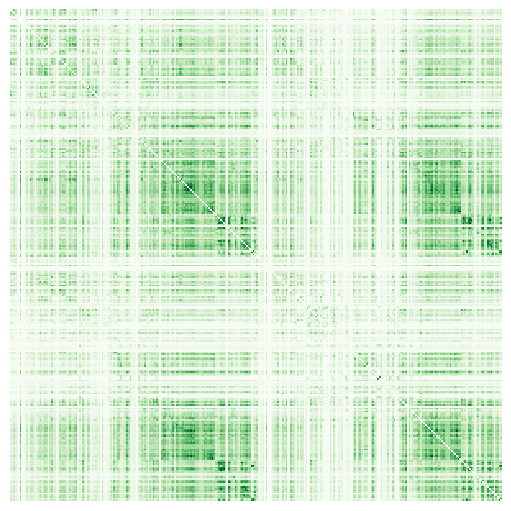

In [9]:
plotting.plot_matrix(red_df['redundancy'][2], colorbar=False, cmap='Greens', )
plt.axis('off')

#plt.savefig(figure_folder + 'fig4A_red.png', transparent=True, dpi=300)
plt.show()

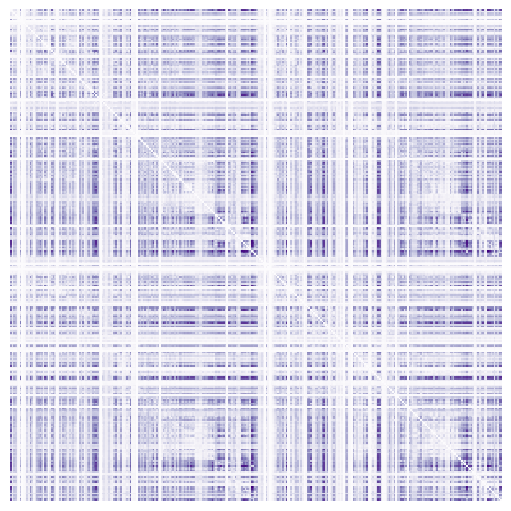

In [10]:
plotting.plot_matrix(syn_df['synergy'][2], colorbar=False, cmap='Purples')
plt.axis('off')

#plt.savefig(figure_folder + 'fig4A_syn.png', transparent=True, dpi=300)
plt.show()

## Panel C

In [14]:
#Load correlation matrices
fc_matrices = load_fc_schaefer300(sup_folder + 'HCP/100unrelated/schaefer300/no_hp/fc/whole/whole_corrs.pck')

#Load representative cycles for one subject (example, adjust path as needed for loop)
# This might need adjustment if paths vary significantly or need dynamic generation
path_template = sup_folder + 'HCP/100unrelated/schaefer300/no_hp/scaffolds/representatives/whole/sub{}.npy'
# cycles = np.load(path, allow_pickle=True) # Keep this structure for loading within the loop

#Load syn and red dataframe
with open(sup_folder + 'HCP/100unrelated/schaefer300/no_hp/info/df_syn_atoms_PHI.pck', 'rb') as f:
    df_red_syn = pk.load(f)

In [15]:
all_subject_metrics = {}
session_to_process = 0 # Assuming session 0 as in the original notebook

for subject in fc_matrices.keys():
    print(f"Processing subject: {subject}...")
    # Load FC matrix for the session
    fc_matrix = fc_matrices[subject][session_to_process]
    
    # Load synergy matrix for the session from the dataframe
    subject_session_data = df_red_syn[(df_red_syn['subject'] == subject) & (df_red_syn['session'] == session_to_process)]
    if subject_session_data.empty:
        print(f"  Skipping subject {subject}, session {session_to_process}: No synergy/redundancy data found.")
        continue
    synergy_matrix = subject_session_data['synergy'].values[0]
    
    # Load representative cycles for the session
    cycles_path = path_template.format(subject)
    try:
        # Cycles file might contain data for multiple sessions
        subject_cycles_all_sessions = np.load(cycles_path, allow_pickle=True)
        if len(subject_cycles_all_sessions) > session_to_process:
             cycles = subject_cycles_all_sessions[session_to_process]
        else:
             print(f"  Skipping subject {subject}, session {session_to_process}: Session data not found in cycles file.")
             continue
    except FileNotFoundError:
        print(f"  Skipping subject {subject}: Cycles file not found at {cycles_path}.")
        continue
    except Exception as e:
        print(f"  Skipping subject {subject}: Error loading cycles - {e}")
        continue
        
    # Ensure matrices are numpy arrays (they might be loaded differently)
    if not isinstance(fc_matrix, np.ndarray): fc_matrix = np.array(fc_matrix)
    if not isinstance(synergy_matrix, np.ndarray): synergy_matrix = np.array(synergy_matrix)
    # Ensure cycles is a list (or compatible structure)
    if not isinstance(cycles, list): cycles = list(cycles) # Adjust if necessary based on actual data structure
        
    # Calculate metrics using the imported function
    subject_metrics = get_subject_synergy_metrics(cycles, synergy_matrix, fc_matrix)
    all_subject_metrics[subject] = subject_metrics
    # print(f"  Metrics: {subject_metrics}") # Optional: print metrics per subject

print("\nFinished calculating metrics for all subjects.")
# Convert dictionary to a more usable format like pandas DataFrame if needed
import pandas as pd
metrics_df = pd.DataFrame.from_dict(all_subject_metrics, orient='index')
print(metrics_df.head())

Processing subject: 100307...
Processing subject: 100408...
Processing subject: 101107...
Processing subject: 101309...
Processing subject: 101915...
Processing subject: 103111...
Processing subject: 103414...
Processing subject: 103818...
Processing subject: 105014...
Processing subject: 105115...
Processing subject: 106016...
Processing subject: 108828...
Processing subject: 110411...
Processing subject: 111312...
Processing subject: 111716...
Processing subject: 113619...
Processing subject: 113922...
Processing subject: 114419...
Processing subject: 115320...
Processing subject: 116524...
Processing subject: 117122...
Processing subject: 118528...
Processing subject: 118730...
Processing subject: 118932...
Processing subject: 120111...
Processing subject: 122317...
Processing subject: 122620...
Processing subject: 123117...
Processing subject: 123925...
Processing subject: 124422...
Processing subject: 125525...
Processing subject: 126325...
Processing subject: 127630...
Processing

## Boxplots

In [17]:
print("Loaded synergy metrics:")
print(metrics_df.head())
print("\nColumn names:")
print(metrics_df.columns.tolist())
print("\nData types:")
print(metrics_df.dtypes)
print("\nShape:")
print(metrics_df.shape)

Loaded synergy metrics:
          border  internal    random  random_fc_matched  random_cycle_internal
100307  0.280237  0.490525  0.230751           0.238823               0.244596
100408  0.442583  0.685480  0.428441           0.405047               0.451880
101107  0.509460  0.832987  0.552426           0.549362               0.562444
101309  0.453136  0.738343  0.368828           0.354816               0.377917
101915  0.455293  0.645775  0.407108           0.396749               0.393655

Column names:
['border', 'internal', 'random', 'random_fc_matched', 'random_cycle_internal']

Data types:
border                   float32
internal                 float32
random                   float32
random_fc_matched        float32
random_cycle_internal    float32
dtype: object

Shape:
(100, 5)


Significant comparisons (FDR-corrected): 4
  Internal vs Border: p = 6.396e-60 *
  Internal vs Random: p = 2.795e-62 *
  Internal vs Random (FC-Matched): p = 3.706e-60 *
  Internal vs Internal Random Cycles: p = 9.529e-61 *


/tmp/ipykernel_3919108/469681441.py:59: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(plot_data, labels=labels, patch_artist=True, showfliers=False,


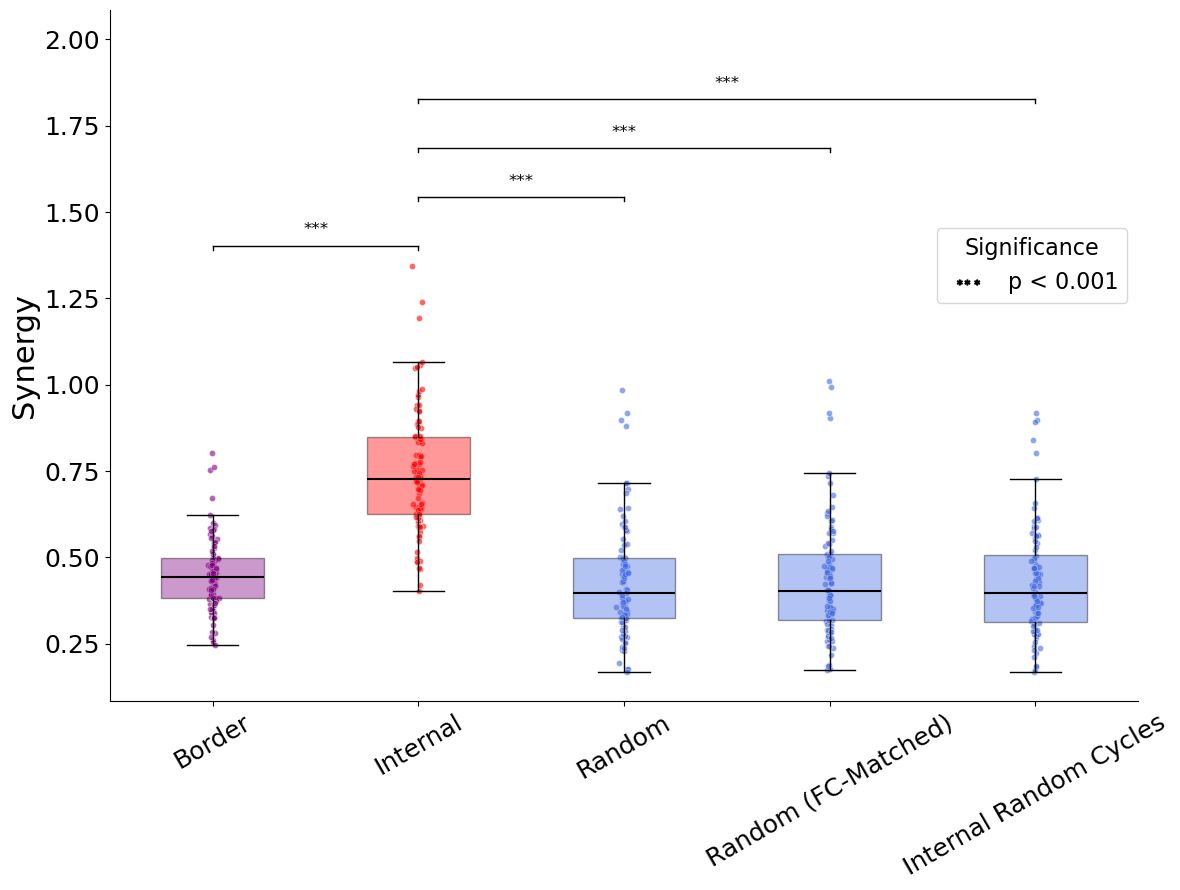


Summary Statistics:
Border: 0.448 ± 0.104
Internal: 0.747 ± 0.173
Random: 0.429 ± 0.159
Random (FC-Matched): 0.434 ± 0.167
Internal Random Cycles: 0.428 ± 0.158


In [19]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D  # <- added for legend markers

# Column mapping
column_names = ['border', 'internal', 'random', 'random_fc_matched', 'random_cycle_internal']
labels = ['Border', 'Internal', 'Random', 'Random (FC-Matched)', 'Internal Random Cycles']

# Prepare data for boxplot
plot_data = [metrics_df[col].dropna() for col in column_names]

# Statistical tests: Compare Internal vs all others
internal_data = metrics_df['internal'].dropna()
comparisons = []
p_values = []

for i, (col, label) in enumerate(zip(column_names, labels)):
    if label != 'Internal':
        other_data = metrics_df[col].dropna()
        
        # Use paired t-test (paired, parametric) as originally used
        try:
            stat, p_val = stats.ttest_rel(internal_data, other_data, alternative='two-sided')
            comparisons.append(('Internal', label))
            p_values.append(p_val)
        except Exception as e:
            print(f"Error comparing Internal vs {label}: {e}")

# Apply FDR correction
if len(p_values) > 0:
    fdr_results = multipletests(p_values, alpha=0.05, method='fdr_bh')
    fdr_corrected_p = fdr_results[1]
    fdr_significant = fdr_results[0]
    
    significant_pairs = [comp for i, comp in enumerate(comparisons) if fdr_significant[i]]
    
    print(f"Significant comparisons (FDR-corrected): {len(significant_pairs)}")
    for i, comp in enumerate(comparisons):
        status = "*" if fdr_significant[i] else "ns"
        print(f"  {comp[0]} vs {comp[1]}: p = {fdr_corrected_p[i]:.3e} {status}")
else:
    significant_pairs = []
    fdr_corrected_p = []

# Create the plot
fig, ax = plt.subplots(figsize=(12, 9))
mpl.rcParams["axes.spines.right"] = False
mpl.rcParams["axes.spines.top"] = False

# Define custom colors: Border = violet, Internal = red, others = blue
custom_colors = ['purple', 'red', 'royalblue', 'royalblue', 'royalblue']

# Create transparent boxplot
box = ax.boxplot(plot_data, labels=labels, patch_artist=True, showfliers=False, 
                 medianprops=dict(color="black", linewidth=1.5))

# Apply custom colors with transparency to boxplots
for patch, color in zip(box['boxes'], custom_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.4)  # Make boxplots transparent
    patch.set_edgecolor('black')
    patch.set_linewidth(1)

# Prepare data for stripplot overlay
stripplot_data = []
stripplot_positions = []
stripplot_colors = []

for i, (data, color) in enumerate(zip(plot_data, custom_colors)):
    stripplot_data.extend(data)
    stripplot_positions.extend([i + 1] * len(data))  # Position 1-indexed for boxplot
    stripplot_colors.extend([color] * len(data))

# Add stripplot overlay
for i, (data, color) in enumerate(zip(plot_data, custom_colors)):
    x_pos = np.random.normal(i + 1, 0.01, len(data))  # Add jitter
    ax.scatter(x_pos, data, color=color, alpha=0.6, s=20, edgecolors='white', linewidth=0.5)

# Add significance annotations
if significant_pairs:
    # Get positions for Internal (position 2, 1-indexed)
    internal_pos = 2
    y_max = max([max(data) for data in plot_data])
    y_range = y_max - min([min(data) for data in plot_data])
    
    annotation_height = y_max + 0.05 * y_range
    height_increment = 0.12 * y_range
    
    annotation_count = 0
    for i, (comp, p_val) in enumerate(zip(comparisons, fdr_corrected_p)):
        if comp in significant_pairs:
            # Find position of the other group
            other_label = comp[1]
            other_pos = labels.index(other_label) + 1
            
            current_height = annotation_height + annotation_count * height_increment
            
            # Draw annotation lines
            ax.plot([internal_pos, other_pos], [current_height, current_height], 'k-', linewidth=1)
            ax.plot([internal_pos, internal_pos], [current_height - 0.01 * y_range, current_height], 'k-', linewidth=1)
            ax.plot([other_pos, other_pos], [current_height - 0.01 * y_range, current_height], 'k-', linewidth=1)
            
            # Add significance stars
            if p_val < 0.001:
                p_text = '***'
            elif p_val < 0.01:
                p_text = '**'
            elif p_val < 0.05:
                p_text = '*'
            else:
                p_text = 'ns'
                
            ax.text((internal_pos + other_pos) / 2, current_height + 0.02 * y_range, p_text, 
                   ha='center', va='bottom', fontsize=12)
            
            annotation_count += 1
    
    # Add legend for p-value mapping (stars -> p ranges)
    legend_handles = [
        Line2D([0], [0], marker='$***$', color='k', linestyle='None', markersize=16),
        ]
    legend_labels = ['p < 0.001']
    ax.legend(legend_handles, legend_labels, title='Significance', loc='best',
              fontsize=16, title_fontsize=16, bbox_to_anchor=(1.0, 0.7))
    
    # Adjust y-axis limits
    ax.set_ylim(ax.get_ylim()[0], annotation_height + annotation_count * height_increment + 0.1 * y_range)

ax.set_ylabel('Synergy', fontsize=22)
ax.tick_params(axis='x', rotation=30, labelsize=18)
ax.tick_params(axis='y', labelsize=18)
plt.tight_layout()
#plt.savefig('../figures/final/fig4/fig4C.png', dpi=300, bbox_inches="tight")
plt.show()

# Summary statistics
print("\nSummary Statistics:")
for i, (col, label) in enumerate(zip(column_names, labels)):
    data = plot_data[i]
    print(f"{label}: {np.mean(data):.3f} ± {np.std(data):.3f}")